# Signal evaluation: does a score predict returns?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leon1706-lol/Aether-quant/blob/main/notebooks/01_signal_evaluation.ipynb)

The checks the project runs on every candidate signal, on three classic crypto signals:

1. **Targets from prices.** Forward returns and their cross-sectional ranks, dated so that a score at D uses only D's close.
2. **The IC report.** The mean daily rank IC, its HAC t-statistic and a block-bootstrap interval.
3. **Returns by quantile and IC decay.**
4. **Purged folds and a leakage audit.** One signal is deliberately leaked, to show the audit catches it.
5. **Factor spanning.** Is the signal more than market (BTC) exposure?

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: install the library (numpy and pandas come with it)
    get_ipython().run_line_magic("pip", 'install -q "aether-quant[notebooks]"')  # noqa: F821
else:  # a clone: run against the checkout's code
    for parent in (Path.cwd(), *Path.cwd().parents):
        if (parent / "aether_quant" / "__init__.py").is_file():
            sys.path.insert(0, str(parent))
            break

In [2]:
import numpy as np
import pandas as pd

from aether_quant import samples, signals

closes = samples.load_sample_prices()
closes = closes.loc["2023-07-13":]  # every coin trades from here (XRP-USD relisted on Coinbase in July 2023)
returns = closes.pct_change(fill_method=None)
print(closes.shape, closes.index.min(), "to", closes.index.max())

(1207, 11) 2023-07-13 to 2026-10-31


## Three signals, each known at D's close

- **Momentum:** the trailing 20-day return.
- **Reversal:** minus the trailing 5-day return.
- **Low volatility:** minus the 30-day realized volatility.

In [3]:
scores = {
    "momentum_20d": closes / closes.shift(20) - 1,
    "reversal_5d": -(closes / closes.shift(5) - 1),
    "low_vol_30d": -returns.rolling(30).std(),
}

## Targets, and the IC report

`forward_rank_targets` builds the long table that `evaluate_signal` reads. With 11 names a day the IC is noisy, which is why the report gives a HAC t-statistic and a bootstrap interval, not just a mean.

In [4]:
targets = signals.forward_rank_targets(closes, horizons=(5, 20))
rows = []
for name, frame in scores.items():
    long = frame.rename_axis(index="date", columns="ticker").reset_index().melt(id_vars="date", var_name="ticker", value_name="score")
    table = targets.merge(long, on=["date", "ticker"]).dropna(subset=["score", "target_rank_20d"])
    report = signals.evaluate_signal(table, score_column="score", splits=("validation",), min_names_per_date=8, bootstrap_draws=300)
    h20 = report["splits"]["validation"]["h20"]
    rows.append({"signal": name, "mean IC (20d)": h20["mean_ic"], "HAC t": h20["hac_t"], "CI low": h20["ci95"][0], "CI high": h20["ci95"][1], "dates": h20["num_dates"]})
pd.DataFrame(rows).set_index("signal").round(3)

,mean IC (20d),HAC t,CI low,CI high,dates
signal,,,,,
momentum_20d,0.003,0.084,-0.057,0.067,1167
reversal_5d,-0.019,-0.930,-0.057,0.017,1182
low_vol_30d,0.043,1.461,-0.012,0.100,1157


## Returns by quantile, and how the IC decays with the horizon

In [5]:
future_5d = signals.forward_returns(closes, 5)
quantiles = signals.quantile_returns(scores["momentum_20d"], future_5d, n_quantiles=3)
print("Mean 5-day forward return by momentum tercile (1 = lowest):")
print((quantiles.mean() * 100).round(3).to_string())

decay = pd.DataFrame({name: signals.ic_decay(frame, closes, horizons=(1, 5, 10, 20, 60)) for name, frame in scores.items()})
decay.index.name = "horizon (days)"
decay.round(3)

Mean 5-day forward return by momentum tercile (1 = lowest):
1    0.372
2    0.497
3    1.052


,momentum_20d,reversal_5d,low_vol_30d
horizon (days),,,
1,-0.010,0.028,0.045
5,0.004,0.004,0.049
10,0.006,0.010,0.043
20,0.003,-0.019,0.043
60,0.017,-0.020,0.103


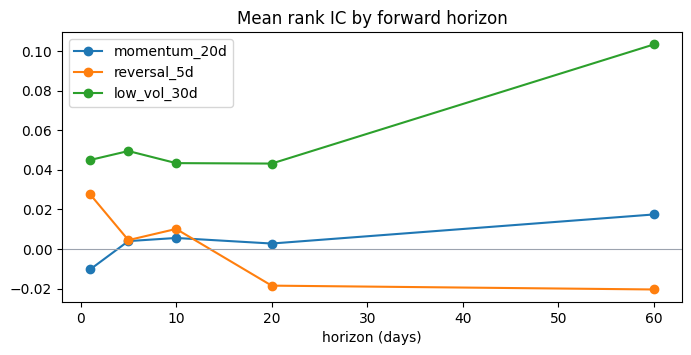

In [6]:
import matplotlib.pyplot as plt

axes = decay.plot(marker="o", figsize=(8, 3.5), title="Mean rank IC by forward horizon")
axes.axhline(0, color="#9ca3af", linewidth=0.8)
plt.show()

## Purged, embargoed folds

A 20-day label overlaps the next 20 days. A test fold must purge training rows whose labels reach into it, and embargo a gap after it. Otherwise the model is graded on the answers it trained on.

In [7]:
row_dates = targets["date"].to_numpy()
folds = signals.purged_embargoed_folds(row_dates, n_folds=4, horizon_days=20, embargo_days=5)
pd.DataFrame(
    [{"fold": n, "validation from": row_dates[val].min(), "validation to": row_dates[val].max(), "train rows": len(train), "validation rows": len(val),
      "purged or embargoed rows": len(row_dates) - len(train) - len(val)} for n, (train, val) in enumerate(folds, 1)]
).set_index("fold")

,validation from,validation to,train rows,validation rows,purged or embargoed rows
fold,,,,,
1,2023-07-13,2024-05-09,9889,3322,55
2,2024-05-10,2025-03-07,9669,3322,275
3,2025-03-08,2026-01-02,9680,3311,275
4,2026-01-03,2026-10-30,9735,3311,220


## A leakage audit catches a leaked signal

`leaked` is the 20-day *forward* return plus noise, a feature that knows the future. The audit's single-feature IC check flags it, while the honest momentum signal passes.

In [8]:
from aether_quant import overfitting

audit_table = targets.merge(scores["momentum_20d"].rename_axis(index="date", columns="ticker").reset_index().melt(id_vars="date", var_name="ticker", value_name="momentum"), on=["date", "ticker"])
audit_table["leaked"] = audit_table["target_return_20d"] + np.random.default_rng(0).normal(0, 0.02, len(audit_table))
audit_table = audit_table.dropna(subset=["momentum", "leaked", "target_rank_20d"]).copy()
audit_table["split"] = np.where(audit_table["date"] < "2025-06-01", "train", "validation")
audit = overfitting.audit_leakage(audit_table, feature_columns=["momentum", "leaked"], min_names=8)
pd.DataFrame(audit["single_feature_ic"]).T.rename(columns={"ic": "mean IC on validation", "flag": "flagged (|IC| > 0.15)"})

,mean IC on validation,flagged (|IC| > 0.15)
momentum,-0.03379,False
leaked,0.913782,True


## Factor spanning: is momentum more than BTC?

Regress the signal's long-short return on the market factor (BTC's daily return), with HAC errors. An alpha whose t-statistic is near zero means the signal's return is market exposure under another name.

In [9]:
rank = scores["momentum_20d"].rank(axis=1, pct=True)
weights = rank.sub(rank.mean(axis=1), axis=0)
weights = weights.div(weights.abs().sum(axis=1), axis=0)
long_short = (weights.shift(1) * returns).sum(axis=1).loc["2023-09-01":]
market = returns["BTCUSD"].loc[long_short.index]
spanning = signals.factor_spanning(long_short, pd.DataFrame({"BTC": market}), periods_per_year=365)
print(f"alpha {spanning['alpha_annual']:.1%} a year, t {spanning['alpha_t']:.2f}; BTC beta {spanning['betas']['BTC']:.2f}; R2 {spanning['r2']:.2f}; {spanning['num_dates']} days")

alpha 33.1% a year, t 1.94; BTC beta -0.03; R2 0.00; 1157 days


**Next:** [02 book construction](02_book_construction.ipynb). Signals become weights, neutral books, sizing and costs.